In [3]:
import shap
import joblib
import pandas as pd
import matplotlib.pyplot as plt

X_train = pd.read_csv("../data/processed/X_train_smote.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")

c:\Users\Asus\Desktop\training project\.venv1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:

print(shap.__version__)

0.51.0


In [5]:
rf = joblib.load("../models/best_model.pkl")

In [6]:
X_test = pd.read_csv("../data/processed/X_test.csv")

In [7]:

explainer = shap.Explainer(rf)

In [8]:
print(explainer.expected_value)

[0.99827023 0.00172977]


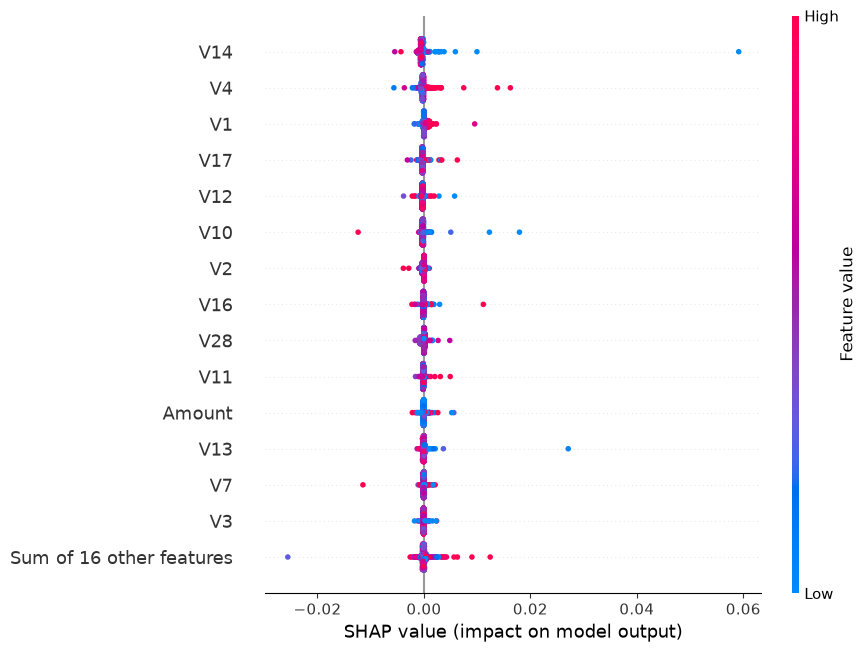

In [9]:
sample = X_test.sample(1000, random_state=42)

shap_values = explainer(sample)

shap.plots.beeswarm(
    shap_values[:, :, 1],
    max_display=15
)

In [10]:
print(type(shap_values))
print(shap_values.shape)

<class 'shap._explanation.Explanation'>
(1000, 30, 2)


In [11]:
print(X_train.shape)
print(X_train.columns)

(227845, 30)
Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount'],
      dtype='str')


In [12]:
print("X_test shape:", X_test.shape)

print("SHAP shape:", shap_values.shape)

X_test shape: (56962, 30)
SHAP shape: (1000, 30, 2)


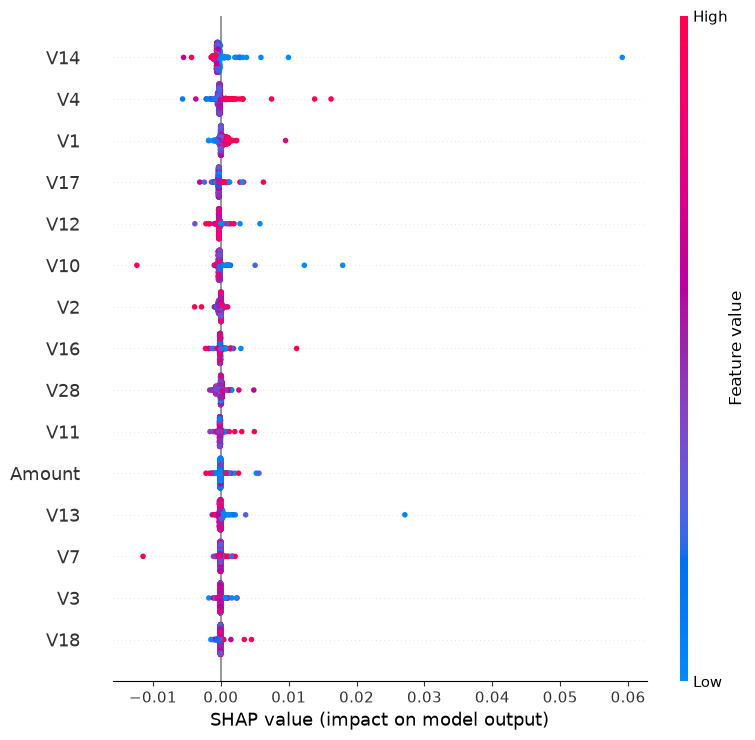

In [13]:
shap.summary_plot(
    shap_values[:, :, 1],
    sample,
    max_display=15
)

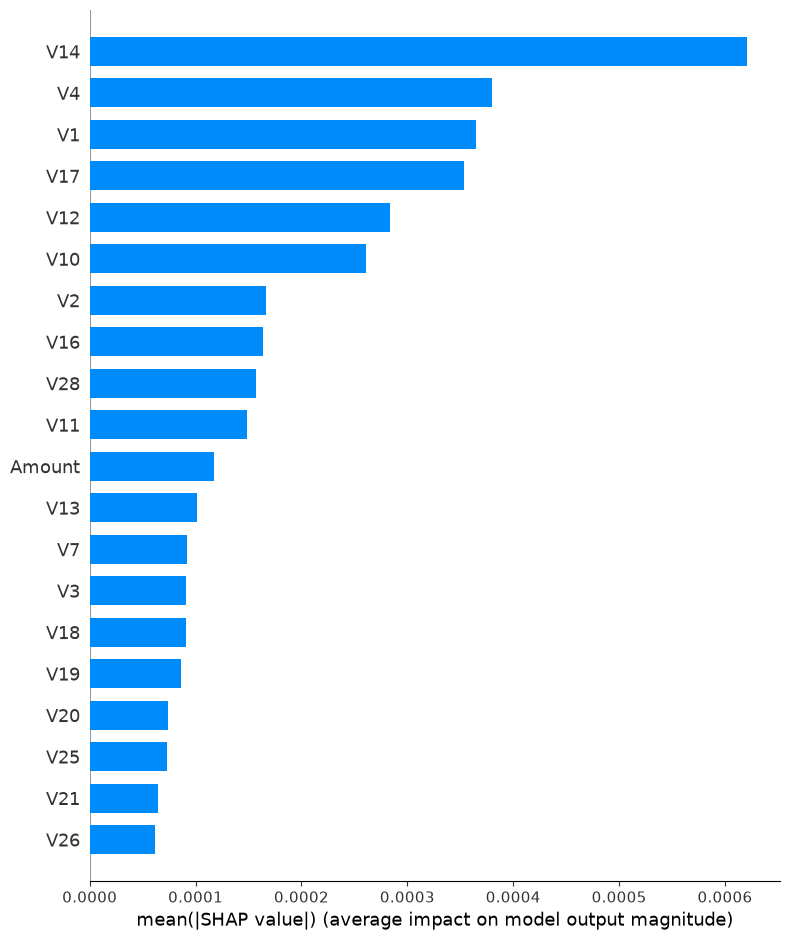

In [13]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_test,
    plot_type="bar"
)

In [14]:
print(type(shap_values))

<class 'shap._explanation.Explanation'>


In [23]:
# import streamlit as st
shap.plots.force(
    shap_values[25, :, 1], 
    matplotlib=True, 
    show=False
)
plt.tight_layout()
plt.savefig(
    "../reports/images/shap_force.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

In [21]:
import os


# Ensure directory exists
os.makedirs("../reports/images", exist_ok=True)

# 1. Build the Explanation object (pure data container)
explanation = shap.Explanation(
    values=shap_values[0, :, 1],
    base_values=explainer.expected_value[1],
    data=X_test.iloc[0],
    feature_names=X_test.columns
)

# 2. Generate and save the plot (`show=False` prevents early display)
shap.plots.waterfall(explanation, show=False)

plt.tight_layout()
plt.savefig(
    "../reports/images/shap_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

In [22]:


# 1. Ensure target directory exists
os.makedirs("../reports/images", exist_ok=True)

# 2. Add show=False to prevent matplotlib from clearing the figure
shap.plots.scatter(shap_values[:, "V14", 1], show=False)

plt.tight_layout()

# 3. Save with a reasonable DPI (300-600)
plt.savefig(
    "../reports/images/shap_scatter.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

In [1]:
shap.summary_plot(
    shap_values[:, :, 1],
    sample,
    max_display=15,
    show=False
)

plt.tight_layout()
plt.savefig(
    "../reports/images/shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

NameError: name 'shap' is not defined